# Cash Game Poker Analytics

## Project Overview

This project analyzes No-Limit Texas Hold'em cash game data to explore player behavior and playing styles.

Using Python, pandas, NumPy, and Matplotlib, the analysis examines preflop participation (VPIP), raising frequency, and aggression.

## Objectives

- Clean and explore poker hand-history data.
- Compare player behavior using VPIP and PFR.
- Visualize relationships between player statistics.
- Identify patterns and communicate data-driven insights.

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

df = pd.read_parquet("data/raw/29.3 parquet.parquet")

print("Dataset shape:", df.shape)
print("Total records:", len(df))
display(df.head())

Dataset shape: (450337, 35)
Total records: 450337


,variant,venue,table,time,time_zone_abbreviation,currency_symbol,currency,author,event,city,...,bring_in,ante_trimming_status,actions,players,antes,blinds_or_straddles,starting_stacks,finishing_stacks,winnings,seats
0,FB,NaN,NaN,NaN,NaN,NaN,NaN,Juho Kim,NaN,NaN,...,NaN,True,[[],"[Bob, Carol, Ted, Alice]","[0.0, 0.0, 0.0, 0.0]","[1.0, 2.0, 0.0, 0.0]","[200.0, 200.0, 200.0, 200.0]",[],[],[]
1,PO,NaN,NaN,NaN,NaN,NaN,USD,Juho Kim,NaN,NaN,...,NaN,True,[[],"[Patrik Antonius, Victor Blom]","[0.0, 0.0]","[500.0, 1000.0]","[1259450.25, 678473.5]",[],[],[]
2,F2L3D,NaN,NaN,NaN,NaN,NaN,NaN,Juho Kim,"2019 World Series of Poker Event #58: $50,000 ...",Las Vegas,...,NaN,True,[[],"[Bryce Yockey, Phil Hui, John Esposito, Josh A...","[0.0, 0.0, 0.0, 0.0]","[75000.0, 150000.0, 0.0, 0.0]","[1180000.0, 4340000.0, 5910000.0, 10765000.0]",[],[],[]
3,NT,NaN,NaN,NaN,NaN,NaN,USD,Juho Kim,Full Tilt Million Dollar Cash Game S4E12,NaN,...,NaN,True,[[],"[Phil Ivey, Patrik Antonius, Tom Dwan]","[500.0, 500.0, 500.0]","[1000.0, 2000.0, 0.0]","[1125600.0, 2000000.0, 553500.0]",[],[],[]
4,NS,NaN,NaN,NaN,NaN,NaN,GBP,Juho Kim,Triton London 2019,London,...,NaN,True,[[],"[Mikita Badziakouski, Liu Ming Zhong, Tan Xuan...","[3000.0, 3000.0, 3000.0, 3000.0, 3000.0, 3000.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 3000.0]","[495000.0, 232000.0, 362000.0, 403000.0, 30100...",[],[],[]


In [3]:
cash_games = df[
    (df["variant"] == "NT") &
    (df["venue"] == "Absolute Poker")
].copy()

print("Cash game hands:", len(cash_games))
print("Columns:", cash_games.shape[1])

Cash game hands: 66830
Columns: 35


## Dataset Overview

The dataset contains 66,830 No-Limit Texas Hold'em cash game hands from Absolute Poker.

The analysis focuses on 107 players with at least 500 recorded hands to provide a more consistent sample for comparing player behavior.

Key variables include player IDs, betting actions, blinds, and recorded winnings.

In [4]:
from collections import Counter

player_actions = Counter()
player_hands = Counter()

for _, hand in cash_games.iterrows():
    players = hand["players"]

    for player in set(players):
        player_hands[player] += 1

    for action in hand["actions"]:
        parts = str(action).split()

        if len(parts) >= 2 and parts[0].startswith("p"):
            player_number = int(parts[0][1:])

            if 1 <= player_number <= len(players):
                player_id = players[player_number - 1]
                player_actions[(player_id, parts[1])] += 1

print("Unique players:", len(player_hands))
print("Total recorded actions:", sum(player_actions.values()))

Unique players: 753
Total recorded actions: 439755


## Player Behavior Analysis

This section examines player participation, preflop raising frequency, and aggression.

Players with at least 500 recorded hands are included in the main analysis to reduce the influence of small sample sizes.

In [5]:
player_stats = pd.DataFrame(
    [
        {
            "player_id": player,
            "hands_played": hands,
            "folds": player_actions[(player, "f")],
            "calls_checks": player_actions[(player, "cc")],
            "raises": player_actions[(player, "cbr")]
        }
        for player, hands in player_hands.items()
    ]
)

player_stats["total_actions"] = (
    player_stats["folds"] +
    player_stats["calls_checks"] +
    player_stats["raises"]
)

player_stats["aggression_pct"] = (
    player_stats["raises"] /
    player_stats["total_actions"] * 100
).round(2)

player_stats = player_stats[player_stats["hands_played"] >= 100].copy()

print("Players with 100+ hands:", len(player_stats))
display(player_stats.head(10))

Players with 100+ hands: 370


,player_id,hands_played,folds,calls_checks,raises,total_actions,aggression_pct
0,+38WdZ4L8J7gkKBgk8Y+aQ,3293,2422,931,1145,4498,25.46
1,EW2DjH0/LLkb08fGS16R8g,410,334,69,114,517,22.05
3,e0S2T57JuvrjeTjtpFyflg,3289,2612,1217,812,4641,17.50
4,3wT3m+GDGtVWU1KR2MWJ1Q,842,614,253,295,1162,25.39
5,H7TvAHMQX+bVR81Nq796DQ,181,135,111,46,292,15.75
6,1KbU9bi+QfP+DGDExSJSKA,430,168,398,280,846,33.10
7,gyLtGhiNFodIr04v8pxZhQ,444,194,538,151,883,17.10
8,bSDJwbTmGA4R+u3vEJdXIA,3816,2985,979,1284,5248,24.47
9,jy4GmGoetUN7Z/wRKRt2ug,312,173,454,118,745,15.84
10,0Pfse71Hl3lQyuzvXqouyg,275,150,179,157,486,32.30


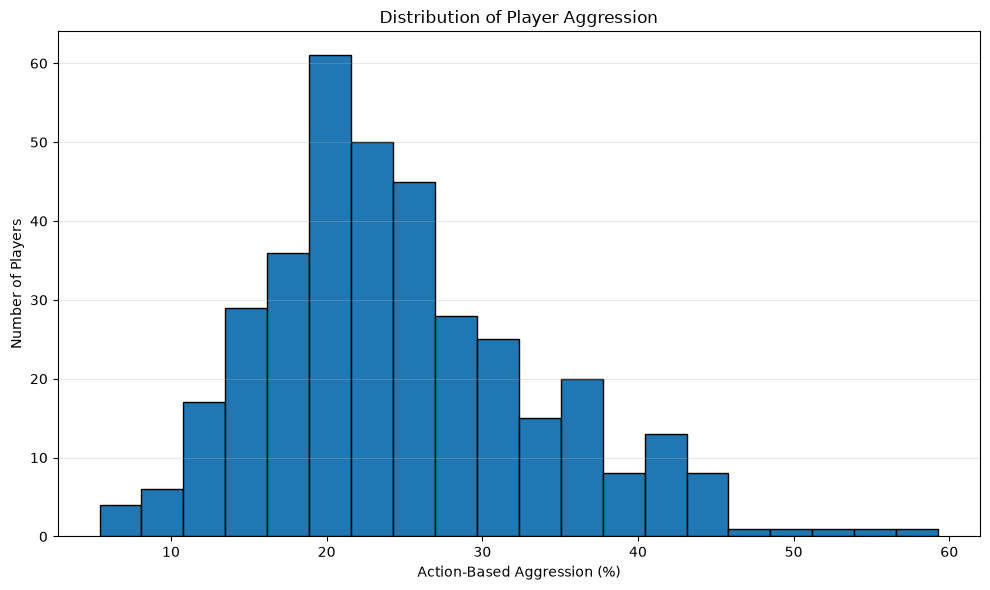

In [6]:
plt.figure(figsize=(10, 6))

plt.hist(player_stats["aggression_pct"], bins=20, edgecolor="black")

plt.title("Distribution of Player Aggression")
plt.xlabel("Action-Based Aggression (%)")
plt.ylabel("Number of Players")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

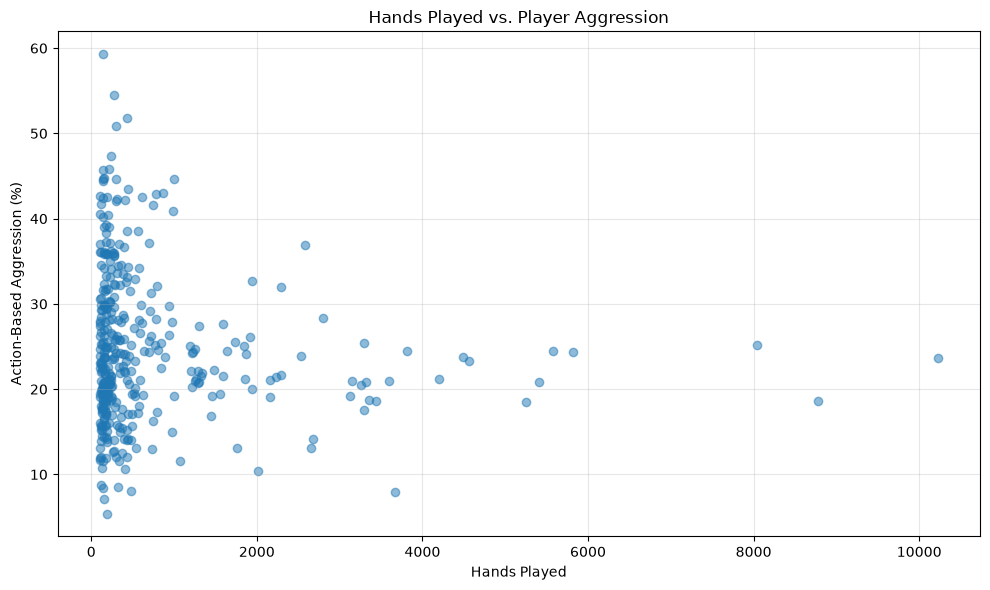

Correlation: -0.103


In [7]:
plt.figure(figsize=(10, 6))

plt.scatter(
    player_stats["hands_played"],
    player_stats["aggression_pct"],
    alpha=0.5
)

plt.title("Hands Played vs. Player Aggression")
plt.xlabel("Hands Played")
plt.ylabel("Action-Based Aggression (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

correlation = player_stats["hands_played"].corr(
    player_stats["aggression_pct"]
)

print("Correlation:", round(correlation, 3))

In [8]:
print("Players:", cash_games["players"].iloc[0])
print("Winnings:", cash_games["winnings"].iloc[0])
print("Type:", type(cash_games["winnings"].iloc[0]))

Players: ['vwPa9NkyrlxHu1v4rBybHw' 'H7TvAHMQX+bVR81Nq796DQ'
 '+38WdZ4L8J7gkKBgk8Y+aQ' 'EW2DjH0/LLkb08fGS16R8g'
 '3wT3m+GDGtVWU1KR2MWJ1Q' 'e0S2T57JuvrjeTjtpFyflg']
Winnings: [  0.   0.   0. 112.   0.   0.]
Type: <class 'numpy.ndarray'>


In [9]:
print("Actions:")
print(cash_games["actions"].iloc[0])

print("\nWinnings:")
print(cash_games["winnings"].iloc[0])

Actions:
['d dh p1 ????' 'd dh p2 ????' 'd dh p3 ????' 'd dh p4 ????'
 'd dh p5 ????' 'd dh p6 ????' 'p3 f' 'p4 cbr 40' 'p5 f' 'p6 cc' 'p1 f'
 'p2 f' 'd db Qd9c5c' 'p4 cbr 88' 'p6 f']

Winnings:
[  0.   0.   0. 112.   0.   0.]


In [10]:
thresholds = [100, 250, 500, 1000, 2000, 5000]

for threshold in thresholds:
    count = (player_stats["hands_played"] >= threshold).sum()
    print(f"{threshold}+ hands: {count} players")

100+ hands: 370 players
250+ hands: 191 players
500+ hands: 107 players
1000+ hands: 63 players
2000+ hands: 32 players
5000+ hands: 7 players


In [11]:
qualified_players = player_stats[player_stats["hands_played"] >= 500].copy()

print("Players:", len(qualified_players))
print(qualified_players[["hands_played", "aggression_pct"]].describe().round(2))

Players: 107
       hands_played  aggression_pct
count        107.00          107.00
mean        1894.32           23.98
std         1752.84            7.12
min          518.00            7.94
25%          743.50           19.76
50%         1270.00           23.34
75%         2292.00           26.44
max        10228.00           44.63


## Key Findings

- Analyzed 66,830 No-Limit Texas Hold'em cash game hands from Absolute Poker.
- Identified 107 players with at least 500 recorded hands.
- Examined player aggression and its relationship with hand volume.
- Found that 87.6% of hands contained recorded payout information.
- Gross payouts alone cannot establish player profitability or BB/100.

## Conclusion

This project demonstrates how Python and pandas can be used to analyze poker player behavior. The findings highlight differences in aggression and playing volume while recognizing the limitations of the available profitability data.

In [12]:
profit_hands = cash_games[
    cash_games["winnings"].apply(len) == cash_games["players"].apply(len)
].copy()

print("Hands with recorded payouts:", len(profit_hands))
print("Percentage of dataset:", round(len(profit_hands) / len(cash_games) * 100, 2))

Hands with recorded payouts: 58538
Percentage of dataset: 87.59


In [13]:
player_winnings = profit_hands[["players", "winnings"]].explode(
    ["players", "winnings"]
)

top_players = (
    player_winnings.groupby("players")["winnings"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_players)

players
YRXyD5Gm275t27NjTtcPtQ    179702.4
X+u4T/E5ANkyZLKm1YjqwQ    148345.3
yOOMTqsR9EFECI4lSNpp1A    112856.6
ZvUzSVOOKZwfU5rLMFTUFg    99049.05
jzhKcsjzeM8Zaw5lPEYSig     98777.7
qnIMl/oVStJvdZUJ+6LHgQ     77510.1
885LXMD+qICcd15BFMNvEg     75141.5
Gmzktdi7SyRTsixKUD1NIw     68816.4
yRCsk8TI2PAKL9gB4LG+/A    67350.55
QE2Vn7Qn2j+IUR+rOKncTA     66414.8
Name: winnings, dtype: object


In [14]:
top_player_stats = player_stats[
    player_stats["player_id"].isin(top_players.index)
]

top_player_stats[["player_id", "hands_played", "aggression_pct"]]

,player_id,hands_played,aggression_pct
17,X+u4T/E5ANkyZLKm1YjqwQ,8043,25.19
19,yRCsk8TI2PAKL9gB4LG+/A,4198,21.22
23,yOOMTqsR9EFECI4lSNpp1A,8774,18.66
49,YRXyD5Gm275t27NjTtcPtQ,10228,23.60
54,885LXMD+qICcd15BFMNvEg,2576,36.90
61,Gmzktdi7SyRTsixKUD1NIw,5251,18.46
73,ZvUzSVOOKZwfU5rLMFTUFg,5823,24.34
90,jzhKcsjzeM8Zaw5lPEYSig,5574,24.44
166,qnIMl/oVStJvdZUJ+6LHgQ,4564,23.34
168,QE2Vn7Qn2j+IUR+rOKncTA,5402,20.81


In [15]:
top_10 = qualified_players[
    qualified_players["player_id"].isin(top_players.index)
]

others = qualified_players[
    ~qualified_players["player_id"].isin(top_players.index)
]

print("Top 10 aggression:", round(top_10["aggression_pct"].mean(), 2))
print("Other players:", round(others["aggression_pct"].mean(), 2))

Top 10 aggression: 23.7
Other players: 24.01


In [16]:
print("Top 10:", round(top_10["hands_played"].mean()))
print("Others:", round(others["hands_played"].mean()))

Top 10: 6043
Others: 1467


In [17]:
payouts = player_winnings.groupby("players")["winnings"].sum()

qualified_players["payout_per_hand"] = (
    qualified_players["player_id"].map(payouts).fillna(0)
    / qualified_players["hands_played"]
)

print(qualified_players.groupby(
    qualified_players["player_id"].isin(top_players.index)
)["payout_per_hand"].mean().round(2))

player_id
False    16.66
True     17.12
Name: payout_per_hand, dtype: float64


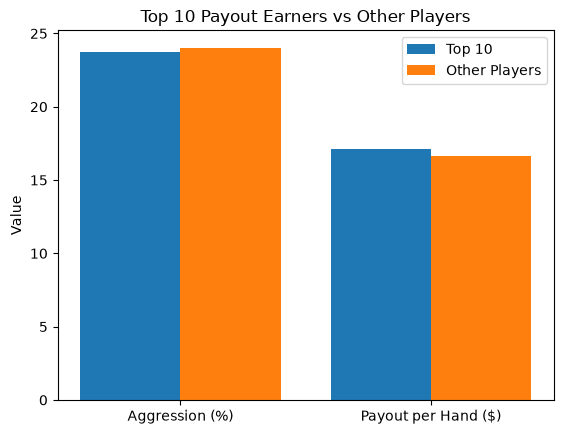

In [18]:
import matplotlib.pyplot as plt

metrics = ["Aggression (%)", "Payout per Hand ($)"]
top_values = [23.70, 17.12]
other_values = [24.01, 16.66]

x = range(len(metrics))

plt.bar([i - 0.2 for i in x], top_values, width=0.4, label="Top 10")
plt.bar([i + 0.2 for i in x], other_values, width=0.4, label="Other Players")

plt.xticks(list(x), metrics)
plt.ylabel("Value")
plt.title("Top 10 Payout Earners vs Other Players")
plt.legend()
plt.show()

## Final Analysis

The top 10 payout earners averaged 6,043 hands compared with 1,467 for other qualified players.

Their aggression rates were nearly identical (23.70% vs. 24.01%), and their gross payouts per hand were similar ($17.12 vs. $16.66).

These results suggest that higher total payouts are strongly associated with greater playing volume rather than higher overall aggression.

## Limitations

Recorded payouts represent gross winnings, not net profit. Therefore, this analysis cannot determine which players were the most profitable.